## Step 1: Clear Session & Release Memory

In [1]:
import tensorflow as tf
import gc

tf.keras.backend.clear_session()
gc.collect()
print('Session cleared. Memory released.')

2026-06-15 09:37:23.902167: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781516244.076553      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781516244.124868      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781516244.522521      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781516244.522557      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781516244.522560      58 computation_placer.cc:177] computation placer alr

Session cleared. Memory released.


## Step 2: Import Libraries

In [2]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageEnhance
from sklearn.utils import shuffle
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

from tensorflow.keras.applications import Xception
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

sns.set_style('darkgrid')
print('All libraries imported successfully.')

All libraries imported successfully.


## Step 3: Configuration

> **Update ONLY this cell to adapt to any dataset.**
> The rest of the notebook runs automatically.

In [3]:
# ============================================================
#  CONFIGURATION — Edit these values for your dataset
# ============================================================

TRAIN_DIR_1 = '/kaggle/input/datasets/azminur2856/alzheimer-mri-dataset/Data'

TRAIN_DIR_2 = '/kaggle/input/datasets/aryansinghal10/alzheimers-multiclass-dataset-equal-and-augmented/combined_images'

IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 0.0001

# How many of the last layers to unfreeze
UNFREEZE_LAST_N_LAYERS = 4

# Train / Validation / Test split
TRAIN_SPLIT = 0.80
VAL_SPLIT = 0.10
# Remaining becomes test set

MODEL_SAVE_PATH = 'Xception_model.keras'

# ============================================================

print(f'Training dir 1 : {TRAIN_DIR_1}')
print(f'Training dir 2 : {TRAIN_DIR_2}')
print(f'Image size     : {IMAGE_SIZE}x{IMAGE_SIZE}')
print(f'Batch size     : {BATCH_SIZE} | Epochs: {EPOCHS}')

Training dir 1 : /kaggle/input/datasets/azminur2856/alzheimer-mri-dataset/Data
Training dir 2 : /kaggle/input/datasets/aryansinghal10/alzheimers-multiclass-dataset-equal-and-augmented/combined_images
Image size     : 224x224
Batch size     : 16 | Epochs: 20


## Step 4: Load Dataset

Automatically reads class folders, collects image paths, and assigns labels.

In [4]:
def load_paths_and_labels(directory):
    """Walk a directory tree and return (paths, labels) lists."""
    paths, labels = [], []

    for label in sorted(os.listdir(directory)):
        label_dir = os.path.join(directory, label)

        if not os.path.isdir(label_dir):
            continue

        for fname in os.listdir(label_dir):
            fpath = os.path.join(label_dir, fname)

            if fname.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.bmp', '.tiff')
            ):
                paths.append(fpath)
                labels.append(label)

    return shuffle(paths, labels, random_state=42)


# Load training (merged) data

train_paths_1, train_labels_1 = load_paths_and_labels(TRAIN_DIR_1)

train_paths_2, train_labels_2 = load_paths_and_labels(TRAIN_DIR_2)

train_paths = train_paths_1 + train_paths_2

train_labels = train_labels_1 + train_labels_2

train_paths, train_labels = shuffle(
    train_paths,
    train_labels,
    random_state=42
)

CLASS_NAMES = sorted(os.listdir(TRAIN_DIR_1))
NUM_CLASSES = len(CLASS_NAMES)

print(f'Classes ({NUM_CLASSES}): {CLASS_NAMES}')
print(f'Total training images: {len(train_paths)}')


# Auto-split train → train / val / test

n = len(train_paths)

train_end = int(n * TRAIN_SPLIT)

val_end = train_end + int(n * VAL_SPLIT)

val_paths, val_labels = (
    train_paths[train_end:val_end],
    train_labels[train_end:val_end]
)

test_paths, test_labels = (
    train_paths[val_end:],
    train_labels[val_end:]
)

train_paths, train_labels = (
    train_paths[:train_end],
    train_labels[:train_end]
)

print(
    f'Split → Train: {len(train_paths)} | '
    f'Val: {len(val_paths)} | '
    f'Test: {len(test_paths)}'
)


# Class distribution

from collections import Counter

dist = Counter(train_labels)

print('\nClass distribution (train):')

for cls, cnt in sorted(dist.items()):
    print(f'  {cls:30s}: {cnt}')

Classes (4): ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
Total training images: 84000
Split → Train: 67200 | Val: 8400 | Test: 8400

Class distribution (train):
  MildDemented                  : 15930
  ModerateDemented              : 15991
  NonDemented                   : 18217
  VeryMildDemented              : 17062


## Step 5: Visualize Sample Images

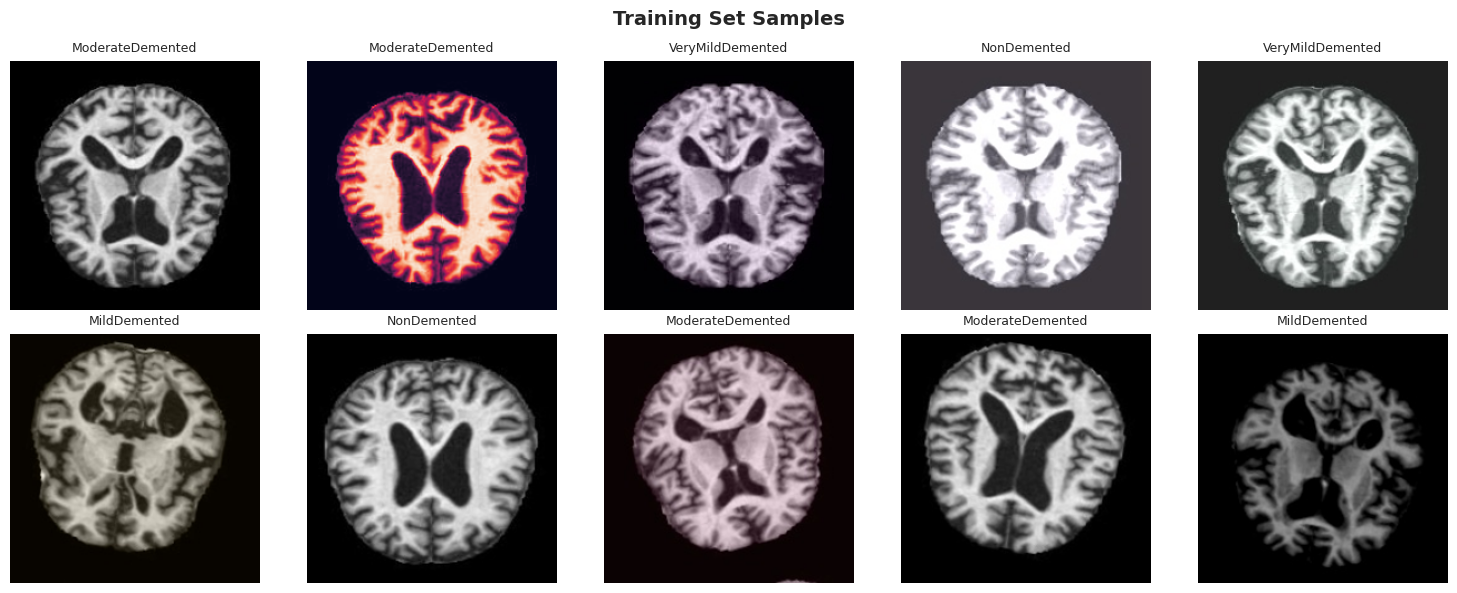

In [5]:
def show_sample_images(paths, labels, n=10, title='Sample Images'):
    indices = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 5
    rows = math.ceil(len(indices) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
    axes = axes.ravel()
    for i, idx in enumerate(indices):
        img = Image.open(paths[idx]).resize((IMAGE_SIZE, IMAGE_SIZE))
        axes[i].imshow(img)
        axes[i].set_title(labels[idx], fontsize=9)
        axes[i].axis('off')
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_sample_images(train_paths, train_labels, n=10, title='Training Set Samples')

In [6]:
# ---- Label encoding --------------------------------------------------------
LABEL_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

def encode_labels(labels):
    return np.array([LABEL_TO_IDX[l] for l in labels])


# ---- Image loading helpers -------------------------------------------------
def augment_image(img_array):
    """Apply brightness + contrast jitter and optional horizontal flip."""
    image = Image.fromarray(np.uint8(img_array * 255))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    if random.random() > 0.5:
        image = image.transpose(Image.FLIP_LEFT_RIGHT)
    return np.array(image) / 255.0


def load_images(paths, augment=False):
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        arr = img_to_array(img) / 255.0
        if augment:
            arr = augment_image(arr)
        images.append(arr)
    return np.array(images)


# ---- Batch generators ------------------------------------------------------
def data_generator(paths, labels, batch_size=BATCH_SIZE, augment=True, epochs=1):
    """Yields (images, encoded_labels) batches, one epoch at a time."""
    for _ in range(epochs):
        paths, labels = shuffle(paths, labels)
        for i in range(0, len(paths), batch_size):
            bp = paths[i:i + batch_size]
            bl = labels[i:i + batch_size]
            yield load_images(bp, augment=augment), encode_labels(bl)


def eval_generator(paths, labels, batch_size=BATCH_SIZE):
    """Non-augmented generator for validation / test inference."""
    for i in range(0, len(paths), batch_size):
        bp = paths[i:i + batch_size]
        bl = labels[i:i + batch_size]
        yield load_images(bp, augment=False), encode_labels(bl)


print('Data generators ready.')

Data generators ready.


In [8]:

base_model = Xception(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze all base layers
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze last N layers for domain-specific fine-tuning
for layer in base_model.layers[-UNFREEZE_LAST_N_LAYERS:]:
    layer.trainable = True

trainable_count = sum(1 for l in base_model.layers if l.trainable)
print(f'Trainable base layers: {trainable_count} / {len(base_model.layers)}')

# Build the classification head
model = Sequential([
    Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
    base_model,
    GlobalAveragePooling2D(),          # Compact feature vector, reduces overfitting
    Dropout(0.4),                      # Regularisation
    Dense(256, activation='relu'),     # High-level feature learning
    Dropout(0.3),                      # Regularisation
    Dense(NUM_CLASSES, activation='softmax')  # Output probabilities
], name='Xception_Classifier')

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy',
    metrics=['sparse_categorical_accuracy']
)

model.summary()

I0000 00:00:1781516300.614738      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Trainable base layers: 4 / 132


Model: "Xception_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 7, 7, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,387,052 (81.59 MB)

 Trainable params: 3,689,220 (14.07 MB)

 Non-trainable params: 17,697,832 (67.51 MB)

## Step 8: Train the Model

In [9]:
steps_per_epoch = math.ceil(len(train_paths) / BATCH_SIZE)
val_steps       = math.ceil(len(val_paths)   / BATCH_SIZE)

callbacks = [
    EarlyStopping(
        monitor='val_sparse_categorical_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        MODEL_SAVE_PATH,
        monitor='val_sparse_categorical_accuracy',
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    data_generator(train_paths, train_labels, augment=True, epochs=EPOCHS),
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=eval_generator(val_paths, val_labels),
    validation_steps=val_steps,
    callbacks=callbacks,
    verbose=1
)

print('\nTraining complete!')

Epoch 1/20


I0000 00:00:1781516314.030957     132 service.cc:152] XLA service 0x7ac484002980 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781516314.031016     132 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1781516315.235212     132 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-15 09:38:42.100429: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-15 09:38:42.325460: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1781516324.796054     132 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the proc

4200/4200 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - loss: 0.8676 - sparse_categorical_accuracy: 0.6088
Epoch 1: val_sparse_categorical_accuracy improved from None to 0.79964, saving model to Xception_model.keras

Epoch 1: finished saving model to Xception_model.keras
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 823s 192ms/step - loss: 0.7227 - sparse_categorical_accuracy: 0.6766 - val_loss: 0.4775 - val_sparse_categorical_accuracy: 0.7996 - learning_rate: 1.0000e-04
Epoch 2/20
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 0.5326 - sparse_categorical_accuracy: 0.7715

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_sparse_categorical_accuracy improved from 0.79964 to 0.87500, saving model to Xception_model.keras

Epoch 2: finished saving model to Xception_model.keras
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 279s 66ms/step - loss: 0.5009 - sparse_categorical_accuracy: 0.7867 - val_loss: 0.3102 - val_sparse_categorical_accuracy: 0.8750 - learning_rate: 1.0000e-04
Epoch 3/20
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.4061 - sparse_categorical_accuracy: 0.8320
Epoch 3: val_sparse_categorical_accuracy did not improve from 0.87500
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 240s 57ms/step - loss: 0.3895 - sparse_categorical_accuracy: 0.8389 - val_loss: 0.2606 - val_sparse_categorical_accuracy: 0.8750 - learning_rate: 1.0000e-04
Epoch 4/20
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.3287 - sparse_categorical_accuracy: 0.8669
Epoch 4: val_sparse_categorical_accuracy improved from 0.87500 to 0.96875, saving model to Xception_model.keras

Epoch 4: finished saving model to Xception_model.keras
4

## Step 9: Training History Plots

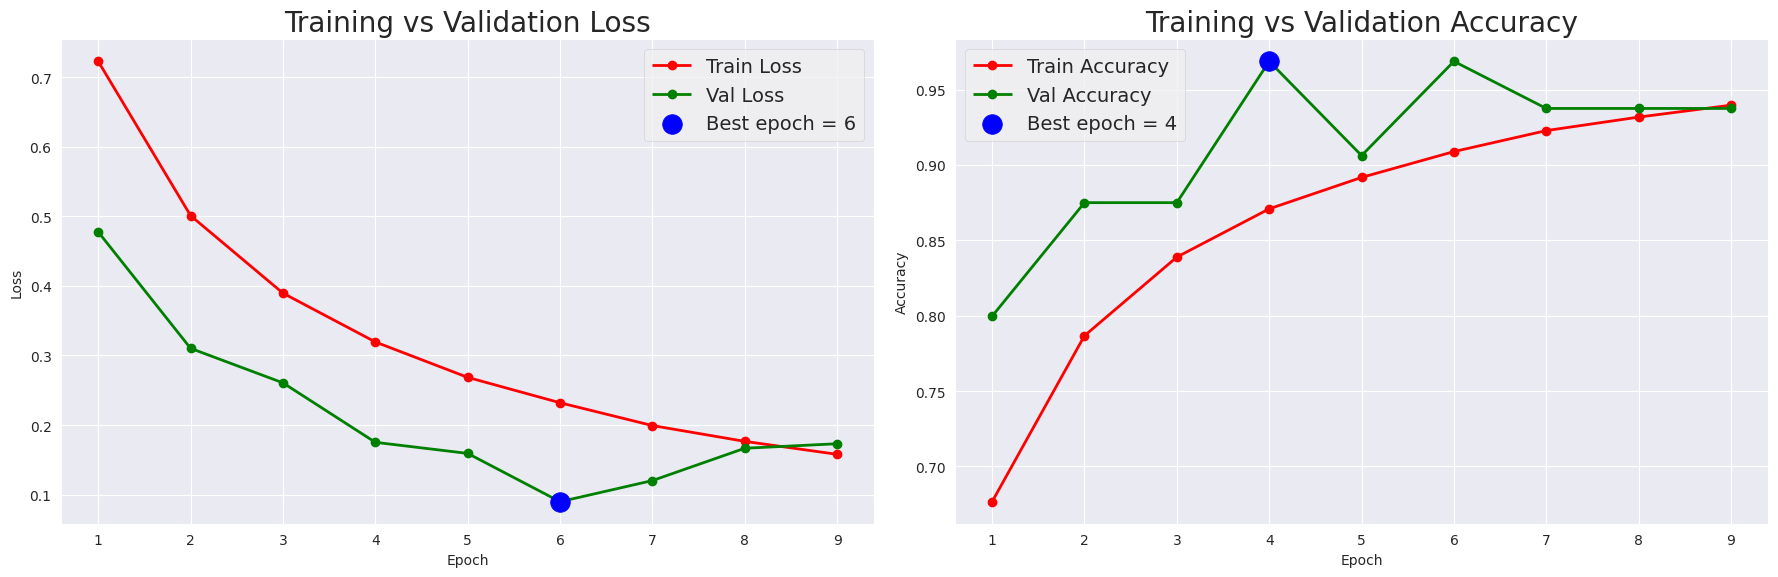

Best val accuracy: 0.9688 at epoch 4
Best val loss    : 0.0898 at epoch 6


In [10]:
def plot_training_history(history):
    acc_key  = 'sparse_categorical_accuracy'
    vacc_key = 'val_sparse_categorical_accuracy'

    tacc  = history.history[acc_key]
    vacc  = history.history[vacc_key]
    tloss = history.history['loss']
    vloss = history.history['val_loss']
    epochs_range = range(1, len(tacc) + 1)

    best_val_loss_ep  = int(np.argmin(vloss))  + 1
    best_val_acc_ep   = int(np.argmax(vacc))   + 1

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    plt.style.use('fivethirtyeight')

    # Loss
    axes[0].plot(epochs_range, tloss, 'r-o', label='Train Loss', linewidth=2)
    axes[0].plot(epochs_range, vloss, 'g-o', label='Val Loss',   linewidth=2)
    axes[0].scatter(best_val_loss_ep, vloss[best_val_loss_ep - 1],
                    s=200, c='blue', zorder=5, label=f'Best epoch = {best_val_loss_ep}')
    axes[0].set_title('Training vs Validation Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()

    # Accuracy
    axes[1].plot(epochs_range, tacc, 'r-o', label='Train Accuracy', linewidth=2)
    axes[1].plot(epochs_range, vacc, 'g-o', label='Val Accuracy',   linewidth=2)
    axes[1].scatter(best_val_acc_ep, vacc[best_val_acc_ep - 1],
                    s=200, c='blue', zorder=5, label=f'Best epoch = {best_val_acc_ep}')
    axes[1].set_title('Training vs Validation Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    print(f'Best val accuracy: {max(vacc):.4f} at epoch {best_val_acc_ep}')
    print(f'Best val loss    : {min(vloss):.4f} at epoch {best_val_loss_ep}')

plot_training_history(history)

## Step 10: Evaluate on Test Set

In [11]:
# Collect all predictions in batches
all_preds, all_true = [], []
for imgs, lbls in eval_generator(test_paths, test_labels):
    preds = model.predict(imgs, verbose=0)
    all_preds.append(preds)
    all_true.extend(lbls)

all_preds      = np.vstack(all_preds)          # shape: (N, num_classes)
pred_classes   = np.argmax(all_preds, axis=1)  # shape: (N,)
true_classes   = np.array(all_true)            # shape: (N,)

print(f'Test samples evaluated: {len(true_classes)}')

# Overall accuracy
test_acc = np.mean(pred_classes == true_classes)
print(f'Test Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)')

Test samples evaluated: 8400
Test Accuracy: 0.9265 (92.65%)


## Step 11: Classification Report

In [12]:
print('Classification Report')
print('=' * 60)
print(classification_report(
    true_classes,
    pred_classes,
    target_names=CLASS_NAMES
))

Classification Report
                  precision    recall  f1-score   support

    MildDemented       0.96      0.94      0.95      1989
ModerateDemented       0.99      1.00      1.00      2003
     NonDemented       0.88      0.91      0.89      2305
VeryMildDemented       0.88      0.87      0.87      2103

        accuracy                           0.93      8400
       macro avg       0.93      0.93      0.93      8400
    weighted avg       0.93      0.93      0.93      8400



## Step 12: Confusion Matrix

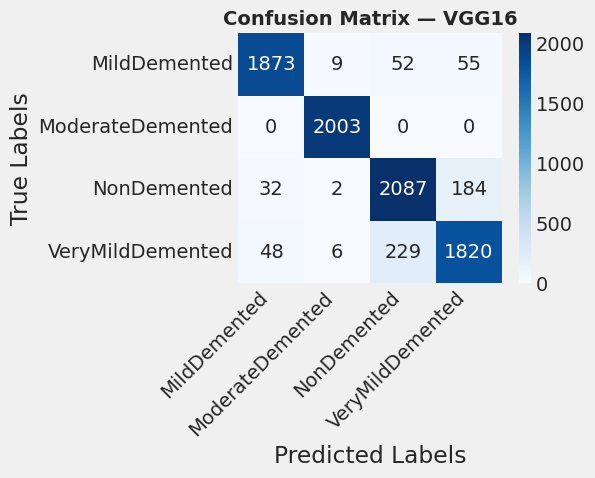

In [13]:
cm = confusion_matrix(true_classes, pred_classes)

plt.figure(figsize=(max(6, NUM_CLASSES * 1.5), max(5, NUM_CLASSES * 1.2)))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title('Confusion Matrix — VGG16', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Step 13: ROC-AUC Curve (Per Class)

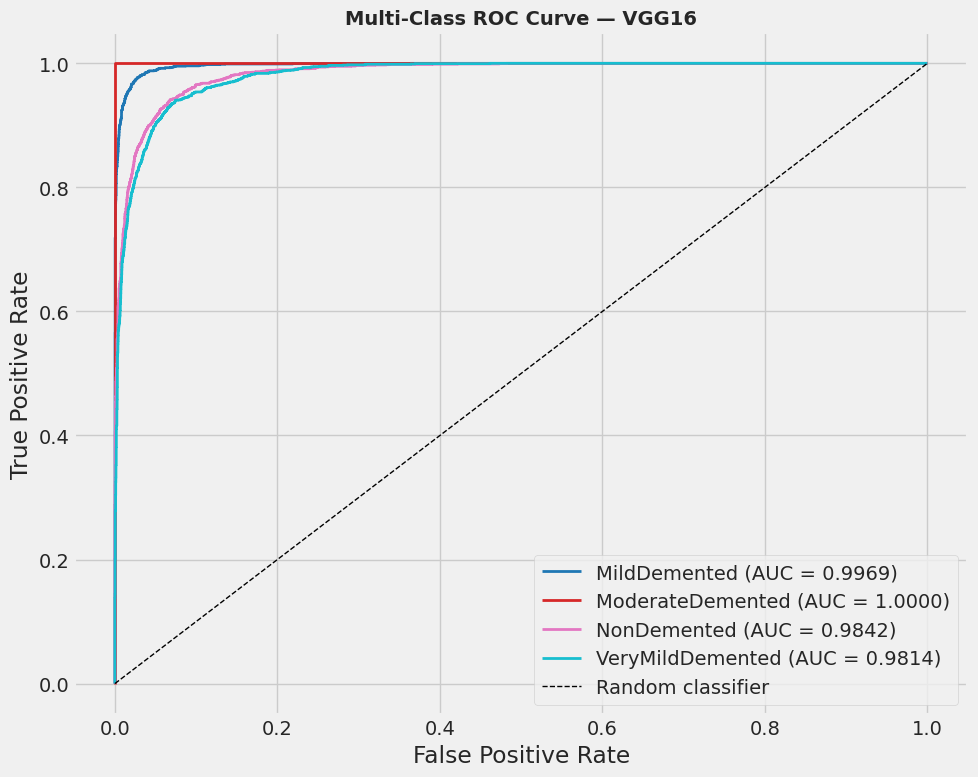


AUC Scores per class:
  MildDemented                  : 0.9969
  ModerateDemented              : 1.0000
  NonDemented                   : 0.9842
  VeryMildDemented              : 0.9814

Mean AUC: 0.9906


In [14]:
# Binarise true labels for one-vs-rest ROC
true_bin = label_binarize(true_classes, classes=np.arange(NUM_CLASSES))

fpr, tpr, roc_auc = {}, {}, {}
for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(true_bin[:, i], all_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, NUM_CLASSES))
for i, color in zip(range(NUM_CLASSES), colors):
    plt.plot(
        fpr[i], tpr[i],
        color=color,
        linewidth=2,
        label=f'{CLASS_NAMES[i]} (AUC = {roc_auc[i]:.4f})'
    )
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
plt.title('Multi-Class ROC Curve — VGG16', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

print('\nAUC Scores per class:')
for i in range(NUM_CLASSES):
    print(f'  {CLASS_NAMES[i]:30s}: {roc_auc[i]:.4f}')
mean_auc = np.mean(list(roc_auc.values()))
print(f'\nMean AUC: {mean_auc:.4f}')

## Step 14: Visualise Predictions on Test Images

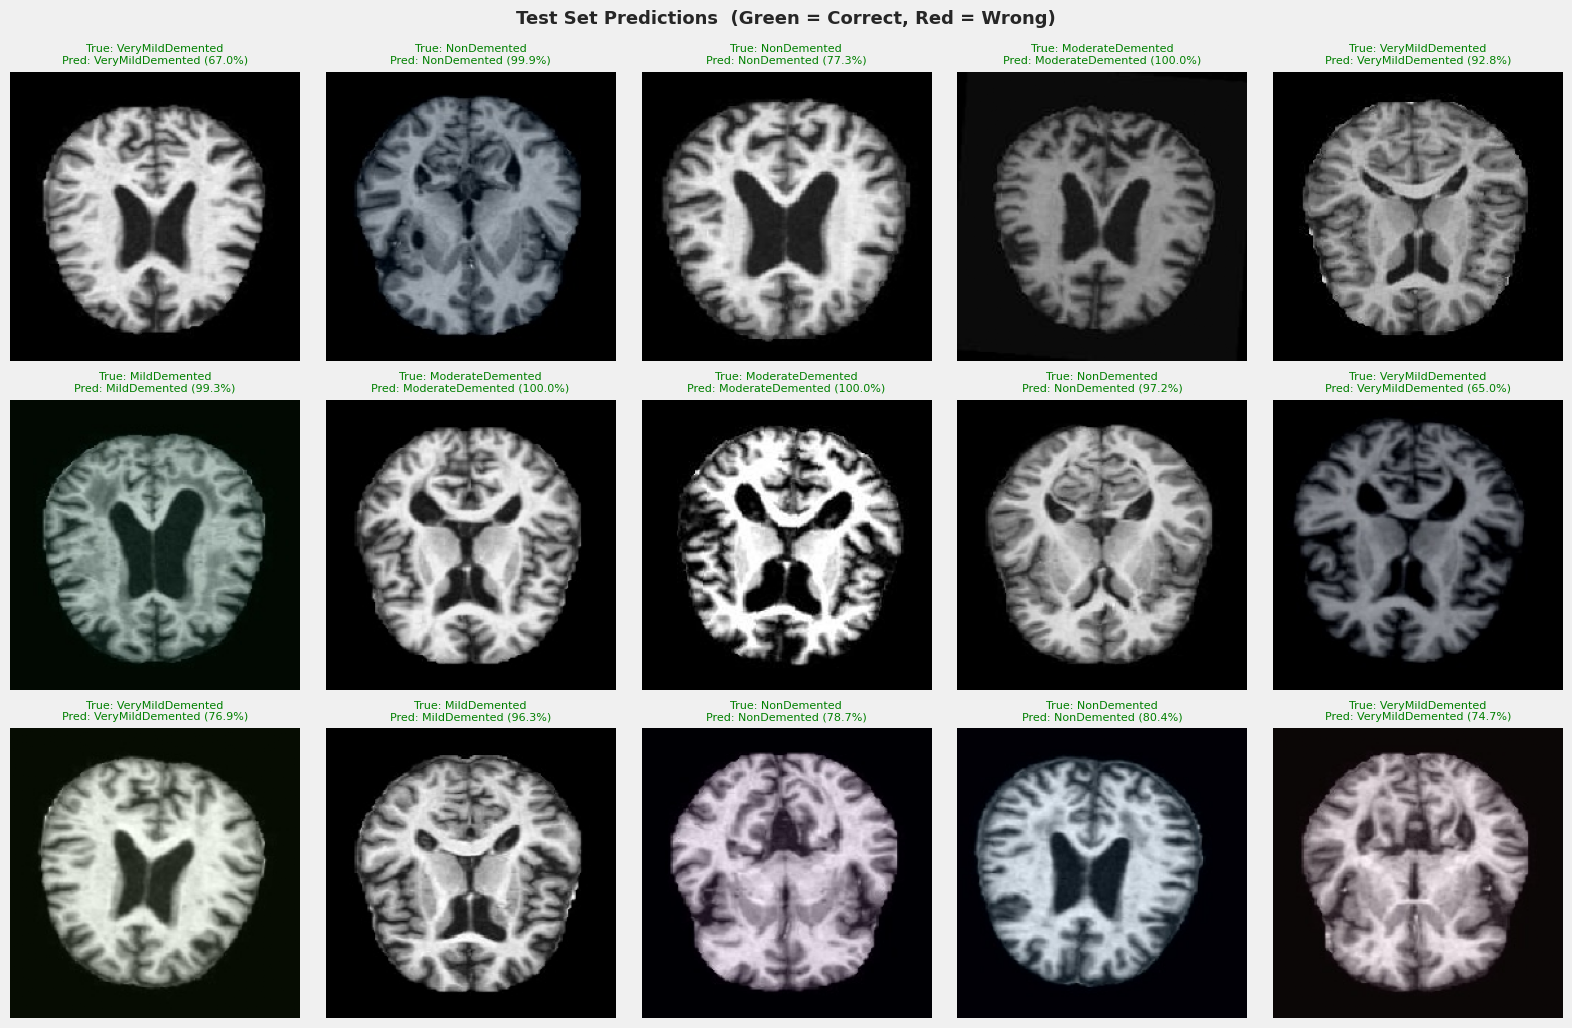

In [15]:
def show_predictions(paths, labels, n=15):
    indices = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 5
    rows = math.ceil(len(indices) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3.5))
    axes = axes.ravel()

    for ax_i, idx in enumerate(indices):
        img_arr = load_images([paths[idx]], augment=False)[0]
        pred    = model.predict(np.expand_dims(img_arr, 0), verbose=0)
        pred_cls  = CLASS_NAMES[np.argmax(pred)]
        true_cls  = labels[idx]
        confidence = np.max(pred) * 100

        axes[ax_i].imshow(img_arr)
        axes[ax_i].axis('off')
        color = 'green' if pred_cls == true_cls else 'red'
        axes[ax_i].set_title(
            f'True: {true_cls}\nPred: {pred_cls} ({confidence:.1f}%)',
            color=color, fontsize=8
        )

    for j in range(ax_i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle('Test Set Predictions  (Green = Correct, Red = Wrong)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_predictions(test_paths, test_labels, n=15)

## Step 15: Single Image Prediction

Actual Class    : VeryMildDemented
Predicted Class : VeryMildDemented
Confidence      : 95.24%


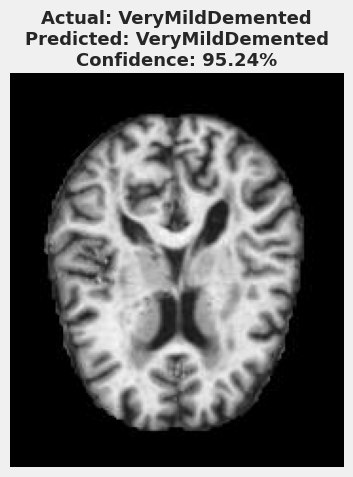


Prediction Probabilities:
MildDemented        : 0.01%
ModerateDemented    : 0.00%
NonDemented         : 4.75%
VeryMildDemented    : 95.24%


In [16]:
# -----------------------------
# Single Test Image Prediction
# -----------------------------

idx = np.random.randint(len(test_paths))

img_path = test_paths[idx]

img = load_img(
    img_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE)
)

arr = img_to_array(img) / 255.0

arr = np.expand_dims(
    arr,
    axis=0
)

preds = model.predict(
    arr,
    verbose=0
)

pred_idx = np.argmax(preds)

pred_class = CLASS_NAMES[pred_idx]

confidence = np.max(preds) * 100

print(f'Actual Class    : {test_labels[idx]}')
print(f'Predicted Class : {pred_class}')
print(f'Confidence      : {confidence:.2f}%')

plt.figure(figsize=(5, 5))

plt.imshow(load_img(img_path))

plt.axis('off')

plt.title(
    f'Actual: {test_labels[idx]}\n'
    f'Predicted: {pred_class}\n'
    f'Confidence: {confidence:.2f}%',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()

plt.show()

print('\nPrediction Probabilities:')

for cls, prob in zip(CLASS_NAMES, preds[0]):
    print(f'{cls:20s}: {prob * 100:.2f}%')

## Step 16: Save & Reload Model

In [17]:
# Best model was already saved by ModelCheckpoint callback.
# Reload it here to confirm everything works.
model = load_model(MODEL_SAVE_PATH)
print(f'Model loaded from: {MODEL_SAVE_PATH}')
print(f'Model input shape : {model.input_shape}')
print(f'Model output shape: {model.output_shape}')
print(f'Total parameters  : {model.count_params():,}')

Model loaded from: Xception_model.keras
Model input shape : (None, 224, 224, 3)
Model output shape: (None, 4)
Total parameters  : 21,387,052
